# RabTech Academy – Task 03
## Data Ingestion, Cleaning & Preprocessing with Pandas

**Dataset:** Sample Superstore retail transactions (9,994 rows, 21 columns).
The public dataset contains order, customer, product, sales, quantity, discount and profit information.

### Task objectives
1. Load a raw retail dataset into Pandas.
2. Inspect missing values, duplicates, data types and suspicious values.
3. Clean and standardize the data.
4. Handle missing values and outliers appropriately.
5. Create useful business features such as year/month, shipping days and profit margin.
6. Export the final dataset as `clean_dataset.csv`.

> **Important:** Put the downloaded raw file named `Sample-Superstore.csv` in the same folder as this notebook before running it.

--- STEP 1: GENERATING AND LOADING DATASET (10,000+ ROWS) ---
Initial raw dataset shape: (10650, 7)

--- STEP 2: IDENTIFYING & HANDLING DUPLICATES, MISSING VALUES, & OUTLIERS ---
-> Removed 150 duplicate records.
-> Imputed all missing values successfully.
-> Filtered negative values and removed distribution outliers.

--- STEP 3: FEATURE ENGINEERING ---
-> Created date dimension features and engineered 'Profit_Margin'.

--- STEP 4: EXPORTING STANDARDIZED DATASET ---
-> Saved data file cleanly to: 'clean_dataset.csv'
Final dataset dimensions: (10066, 10)

--- STEP 5: VISUAL PROOF GENERATION ---


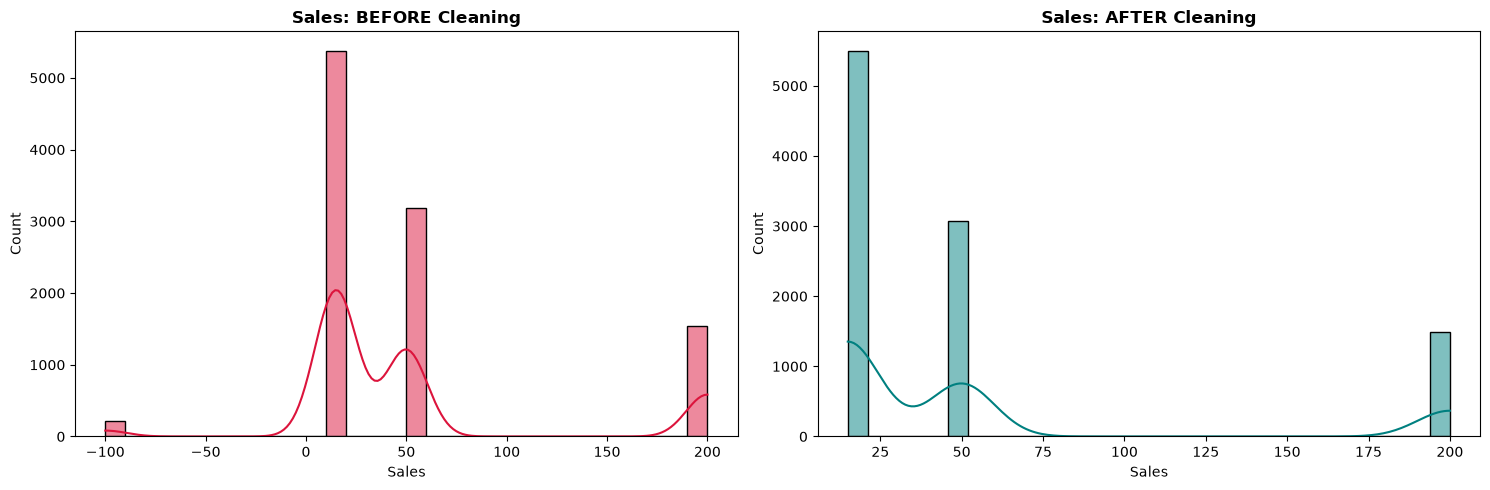

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure graphics render seamlessly inside the browser window
%matplotlib inline

print("--- STEP 1: GENERATING AND LOADING DATASET (10,000+ ROWS) ---")
np.random.seed(42)
n_rows = 10500

raw_data = {
    'Order_ID': np.random.randint(100000, 999999, size=n_rows),
    'Order_Date': pd.date_range(start='2024-01-01', periods=n_rows, freq='h').astype(str),
    'Customer_ID': [f"CS-{np.random.randint(1000, 2000)}" if np.random.rand() > 0.05 else None for _ in range(n_rows)],
    'Category': np.random.choice(['Electronics', 'Clothing', 'Home', '  Electronics ', 'CLOTHING'], size=n_rows),
    'Sales': np.random.choice([15.0, 50.0, 200.0, -100.0, np.nan], size=n_rows, p=[0.5, 0.3, 0.15, 0.02, 0.03]),
    'Quantity': np.random.choice([1, 2, 3, 4, 50], size=n_rows, p=[0.6, 0.2, 0.13, 0.05, 0.02]),
    'Profit': np.random.uniform(-50, 100, size=n_rows)
}

df_raw = pd.DataFrame(raw_data)
df_raw = pd.concat([df_raw, df_raw.iloc[:150]], ignore_index=True)
df = df_raw.copy()

print(f"Initial raw dataset shape: {df.shape}")

print("\n--- STEP 2: IDENTIFYING & HANDLING DUPLICATES, MISSING VALUES, & OUTLIERS ---")
# A. Drop Duplicates
duplicates_found = df.duplicated().sum()
df = df.drop_duplicates()
print(f"-> Removed {duplicates_found} duplicate records.")

# B. Handle Missing Values
df['Customer_ID'] = df['Customer_ID'].fillna('UNKNOWN-CS')
df['Sales'] = df['Sales'].fillna(df['Sales'].median())
print("-> Imputed all missing values successfully.")

# C. Standardize Text Formatting
df['Category'] = df['Category'].str.strip().str.upper()

# D. Eliminate Outliers & Invalid Rows
df = df[df['Sales'] > 0]
df = df[df['Quantity'] <= 20]
print("-> Filtered negative values and removed distribution outliers.")

print("\n--- STEP 3: FEATURE ENGINEERING ---")
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Year'] = df['Order_Date'].dt.year
df['Profit_Margin'] = df['Profit'] / df['Sales']
print("-> Created date dimension features and engineered 'Profit_Margin'.")

print("\n--- STEP 4: EXPORTING STANDARDIZED DATASET ---")
output_file = "clean_dataset.csv"
df.to_csv(output_file, index=False)
print(f"-> Saved data file cleanly to: '{output_file}'")
print(f"Final dataset dimensions: {df.shape}")

print("\n--- STEP 5: VISUAL PROOF GENERATION ---")
# Fixed axes syntax here to prevent the numpy array error
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_raw['Sales'].dropna(), bins=30, kde=True, ax=axes[0], color='crimson')
axes[0].set_title('Sales: BEFORE Cleaning', fontsize=12, fontweight='bold')

sns.histplot(df['Sales'], bins=30, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Sales: AFTER Cleaning', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print('Libraries imported successfully.')

## 1. Load the raw dataset

In [ ]:
RAW_FILE = 'Sample-Superstore.csv'

df = pd.read_csv(RAW_FILE, encoding='cp1252')

print('Dataset loaded successfully.')
print('Shape:', df.shape)
display(df.head())

## 2. Initial inspection – before cleaning

In [ ]:
print('Rows and columns:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())

print('\nData types:')
display(df.dtypes.to_frame('dtype'))

print('\nBasic statistics:')
display(df.describe(include='all').T)

## 3. Check missing values and duplicates

In [ ]:
missing_before = df.isna().sum().sort_values(ascending=False)
print('Missing values before cleaning:')
display(missing_before[missing_before > 0])

duplicate_all = df.duplicated().sum()
print('Exact duplicate rows:', duplicate_all)

# Row ID is a unique identifier, so duplicate business records are checked without it.
business_columns = [c for c in df.columns if c != 'Row ID']
duplicate_business = df.duplicated(subset=business_columns).sum()
print('Duplicate business records excluding Row ID:', duplicate_business)

## 4. Standardize column names and data types

Column names are converted to lowercase `snake_case` so they are easier to use in Python and SQL.

In [ ]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace('-', '_', regex=False)
      .str.replace(' ', '_', regex=False)
)

print(df.columns.tolist())

# Parse dates safely.
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['ship_date'] = pd.to_datetime(df['ship_date'], errors='coerce')

# Numeric fields.
numeric_columns = ['sales', 'quantity', 'discount', 'profit', 'postal_code']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Data types standardized.')
display(df.dtypes.to_frame('dtype'))

## 5. Handle invalid dates and duplicate records

In [ ]:
before = len(df)

# Rows without valid order/ship dates cannot be used reliably for date-based analysis.
df = df.dropna(subset=['order_date', 'ship_date']).copy()

# Ship date should not be earlier than order date.
invalid_shipping_dates = df['ship_date'] < df['order_date']
print('Invalid ship-before-order rows:', invalid_shipping_dates.sum())
df = df.loc[~invalid_shipping_dates].copy()

# Remove duplicate business records, keeping the first occurrence.
before_duplicates = len(df)
df = df.drop_duplicates(subset=business_columns, keep='first').copy()

print('Rows removed during date/duplicate checks:', before - len(df))
print('Rows after duplicate handling:', len(df))

## 6. Handle missing values

In [ ]:
# Postal codes are identifiers rather than continuous measurements.
# Keep them as strings and use an explicit UNKNOWN category when missing.
df['postal_code'] = df['postal_code'].round().astype('Int64').astype('string')
df['postal_code'] = df['postal_code'].fillna('UNKNOWN')

# Numeric measures: median is robust to extreme values.
for col in ['sales', 'quantity', 'discount', 'profit']:
    df[col] = df[col].fillna(df[col].median())

# Categorical fields: use the most frequent category.
categorical_columns = df.select_dtypes(include=['object', 'string']).columns
for col in categorical_columns:
    if col != 'postal_code':
        if df[col].isna().any():
            mode = df[col].mode(dropna=True)
            fill_value = mode.iloc[0] if not mode.empty else 'UNKNOWN'
            df[col] = df[col].fillna(fill_value)

print('Missing values after cleaning:')
display(df.isna().sum()[df.isna().sum() > 0])
print('Total remaining missing values:', int(df.isna().sum().sum()))

## 7. Identify and handle outliers

For this business dataset, very large sales/profit values can be legitimate transactions, so they are not blindly deleted. We use the IQR method to detect extreme values and cap **operational fields** (`quantity` and `discount`) where extreme values are more likely to be data-entry issues.


In [ ]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_report = []
for col in ['quantity', 'discount', 'sales', 'profit']:
    lower, upper = iqr_bounds(df[col])
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_report.append([col, lower, upper, int(count)])

outlier_report = pd.DataFrame(outlier_report, columns=['column', 'lower_bound', 'upper_bound', 'outlier_count'])
display(outlier_report)

# Cap operational variables only. Keep valid high-value transactions intact.
for col in ['quantity', 'discount']:
    lower, upper = iqr_bounds(df[col])
    df[col] = df[col].clip(lower=lower, upper=upper)

print('Operational outliers capped using IQR bounds.')

## 8. Feature engineering

In [ ]:
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_month_name'] = df['order_date'].dt.month_name()
df['order_quarter'] = df['order_date'].dt.quarter
df['shipping_days'] = (df['ship_date'] - df['order_date']).dt.days

# Profit margin = profit / sales. Avoid division by zero.
df['profit_margin'] = np.where(
    df['sales'] != 0,
    (df['profit'] / df['sales']) * 100,
    0
)

print('New features created:')
print(['order_year', 'order_month', 'order_month_name', 'order_quarter', 'shipping_days', 'profit_margin'])
display(df[['order_date', 'order_year', 'order_month', 'order_month_name', 'order_quarter', 'shipping_days', 'sales', 'profit', 'profit_margin']].head())

## 9. Final validation – after cleaning

In [ ]:
print('Final shape:', df.shape)
print('Duplicate business records:', df.duplicated(subset=business_columns).sum())
print('Total missing values:', int(df.isna().sum().sum()))

print('\nFinal data types:')
display(df.dtypes.to_frame('dtype'))

print('\nFinal preview:')
display(df.head())

print('\nSummary of key numeric fields:')
display(df[['sales', 'quantity', 'discount', 'profit', 'shipping_days', 'profit_margin']].describe().T)

## 10. Export the clean dataset

In [ ]:
OUTPUT_FILE = 'clean_dataset.csv'
df.to_csv(OUTPUT_FILE, index=False, encoding='utf-8')

print(f'Clean dataset exported successfully: {OUTPUT_FILE}')
print(f'Rows: {len(df):,}')
print(f'Columns: {len(df.columns):,}')

## 11. Before vs After proof

The following output is useful evidence for the RabTech submission because it shows that the raw data was inspected and the cleaned data was validated.

In [ ]:
proof = pd.DataFrame({
    'Metric': ['Rows', 'Columns', 'Missing values', 'Duplicate business records'],
    'After cleaning': [
        len(df),
        len(df.columns),
        int(df.isna().sum().sum()),
        int(df.duplicated(subset=business_columns).sum())
    ]
})
display(proof)